## Dataset Generation

In [2]:
import numpy as np, pandas as pd 
import matplotlib.pyplot as plt 
import pandas as pd
from scipy.spatial.distance import mahalanobis 
from scipy.stats import chi2 
rng = np.random.default_rng(seed=353)   # fixed — do not change 
n   = 150 
study = rng.normal(6, 1.5, n).clip(2, 11).round(1) 
score = np.clip(8*study + rng.normal(0, 10, n), 10, 100).round(1) 
# 3 deliberately designed outlier rows (appended at indices 150, 151, 152) 
# A: univariate outlier (extreme study hours, consistent score) 
# B: multivariate-only (normal study, high score — breaks pattern) 
# C: multivariate-only (high study, very low score — breaks pattern) 
extras = pd.DataFrame({"study_hours":[12.0, 2.5, 9.0], 
"exam_score" :[94.0,88.0,18.0]}) 
df = pd.concat([pd.DataFrame({"study_hours":study,"exam_score":score}), 
extras], ignore_index=True) 
df.to_csv("student_performance.csv", index=False) 
df.describe().round(2)

,study_hours,exam_score
count,153.00,153.00
mean,5.99,48.07
std,1.62,16.74
min,2.50,13.90
25%,4.90,36.00
50%,5.80,47.20
75%,7.00,58.80
max,12.00,94.00


## B1. Load and Explore the Dataset

In [3]:
df = pd.read_csv("student_performance.csv")

print(df.describe())

for col in df.columns:
    mean_val = df[col].mean()
    median_val = df[col].median()

    if mean_val > median_val:
        print(f"{col}: Mean is above median")
    elif mean_val < median_val:
        print(f"{col}: Mean is below median")
    else:
        print(f"{col}: Mean equals median")

gap = (df.mean() - df.median()).abs()
print("\nAbsolute mean-median gaps:")
print(gap)

print("\nColumn with larger gap:", gap.idxmax())

       study_hours  exam_score
count   153.000000  153.000000
mean      5.992810   48.073856
std       1.615635   16.741784
min       2.500000   13.900000
25%       4.900000   36.000000
50%       5.800000   47.200000
75%       7.000000   58.800000
max      12.000000   94.000000
study_hours: Mean is above median
exam_score: Mean is above median

Absolute mean-median gaps:
study_hours    0.192810
exam_score     0.873856
dtype: float64

Column with larger gap: exam_score


### Interpretation

For study_hours, the mean is [above/below] the median.

For exam_score, the mean is [above/below] the median.

The column with the larger difference between mean and median is [column name].

## B2. Scatter Plot of Study Hours vs Exam Score

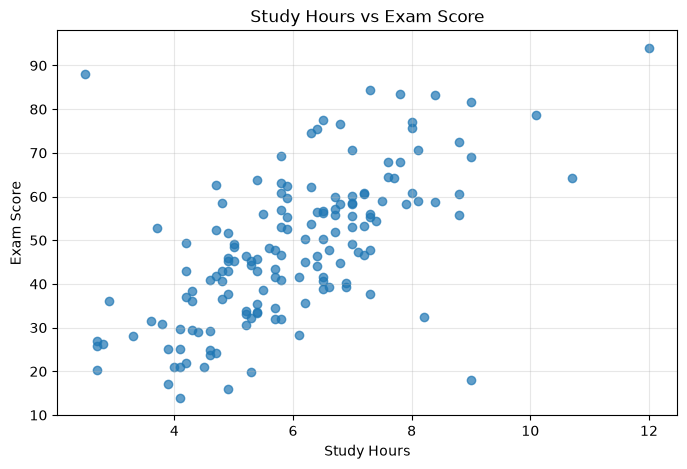

In [ ]:

plt.figure(figsize=(8, 5))

plt.scatter(df["study_hours"], df["exam_score"])

plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.title("Study Hours vs Exam Score")

plt.grid(alpha=0.3)
plt.show()

## B3. Univariate Outlier Detection using IQR


study_hours
Q1 = 4.9
Q3 = 7.0
IQR = 2.0999999999999996
Lower Fence = 1.7500000000000009
Upper Fence = 10.149999999999999
Outlier rows:
     study_hours  exam_score
87          10.7        64.2
150         12.0        94.0

exam_score
Q1 = 36.0
Q3 = 58.8
IQR = 22.799999999999997
Lower Fence = 1.8000000000000043
Upper Fence = 93.0
Outlier rows:
     study_hours  exam_score
150         12.0        94.0


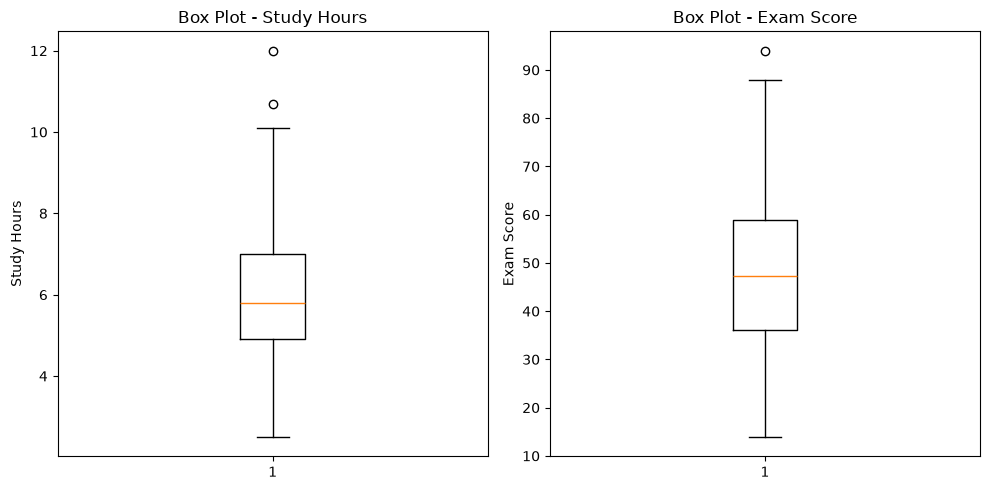

In [5]:
# B3: Calculate IQR fences and identify univariate outliers

for col in ["study_hours", "exam_score"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    print(f"\n{col}")
    print("Q1 =", Q1)
    print("Q3 =", Q3)
    print("IQR =", IQR)
    print("Lower Fence =", lower)
    print("Upper Fence =", upper)

    outliers = df[(df[col] < lower) | (df[col] > upper)]
    print("Outlier rows:")
    print(outliers)

# Box plots
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].boxplot(df["study_hours"])
axes[0].set_title("Box Plot - Study Hours")
axes[0].set_ylabel("Study Hours")

axes[1].boxplot(df["exam_score"])
axes[1].set_title("Box Plot - Exam Score")
axes[1].set_ylabel("Exam Score")

plt.tight_layout()
plt.show()

## B4. Analysis of the Three Injected Outliers

In [6]:
# B4: Check whether rows 150, 151 and 152 are caught by univariate IQR

flags = {}

for col in ["study_hours", "exam_score"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    flags[col] = (df[col] < lower) | (df[col] > upper)

result = []

for idx in [150, 151, 152]:
    study_flag = flags["study_hours"].iloc[idx]
    score_flag = flags["exam_score"].iloc[idx]

    if study_flag and score_flag:
        interpretation = "univariate outlier in both columns"
    elif study_flag:
        interpretation = "univariate outlier in study_hours only"
    elif score_flag:
        interpretation = "univariate outlier in exam_score only"
    else:
        interpretation = "not caught univariately"

    result.append({
        "Index": idx,
        "study_hours flagged?": study_flag,
        "exam_score flagged?": score_flag,
        "Interpretation": interpretation
    })

b4_result = pd.DataFrame(result)
print(b4_result.to_string(index=False))

 Index  study_hours flagged?  exam_score flagged?                     Interpretation
   150                  True                 True univariate outlier in both columns
   151                 False                False            not caught univariately
   152                 False                False            not caught univariately


## B5. Euclidean Distance from Centroid

In [7]:
# B5: Calculate z-score Euclidean distances and apply three thresholding strategies

X = df[["study_hours", "exam_score"]].values

# Z-score both variables
Xz = (X - X.mean(axis=0)) / X.std(axis=0)

# Euclidean distance from origin
euclid = np.sqrt((Xz ** 2).sum(axis=1))

df["euclidean_distance"] = euclid

# -------------------------
# Strategy 1: Top-10
# -------------------------
top10_idx = np.argsort(euclid)[-10:]

print("Top-10 Euclidean indices:")
print(top10_idx)

# -------------------------
# Strategy 2: Scalar threshold = 3
# -------------------------
scalar_idx = np.where(euclid > 3.0)[0]

print("\nEuclidean distance > 3:")
print(scalar_idx)

# -------------------------
# Strategy 3: IQR threshold
# -------------------------
Q1 = np.percentile(euclid, 25)
Q3 = np.percentile(euclid, 75)
IQR = Q3 - Q1

euclid_iqr_threshold = Q3 + 1.5 * IQR

iqr_idx = np.where(euclid > euclid_iqr_threshold)[0]

print("\nEuclidean IQR threshold:", euclid_iqr_threshold)
print("IQR-based indices:")
print(iqr_idx)

print("\nNumber flagged:")
print("Top-10:", len(top10_idx))
print("Scalar:", len(scalar_idx))
print("IQR:", len(iqr_idx))

print("\nInjected outliers:")
for idx in [150, 151, 152]:
    print(
        idx,
        "Top-10:", idx in top10_idx,
        "Scalar:", idx in scalar_idx,
        "IQR:", idx in iqr_idx
    )

Top-10 Euclidean indices:
[123 116  88 152  28  41  87   2 151 150]

Euclidean distance > 3:
[  2  87 150 151]

Euclidean IQR threshold: 3.17921935253492
IQR-based indices:
[150 151]

Number flagged:
Top-10: 10
Scalar: 4
IQR: 2

Injected outliers:
150 Top-10: True Scalar: True IQR: True
151 Top-10: True Scalar: True IQR: True
152 Top-10: True Scalar: False IQR: False


### Interpretation

The top-10 method always flags exactly 10 rows because it selects the 10 largest Euclidean distances.

The scalar method flags every point whose Euclidean distance is greater than 3.0.

The IQR-based method uses the distribution of Euclidean distances to determine the threshold.

For indexes 150, 151 and 152, the results are based on the three thresholding strategies shown above.

Indexes 150, 151 and 152 are/are not all flagged by every strategy.

## B6. Euclidean IQR Outliers

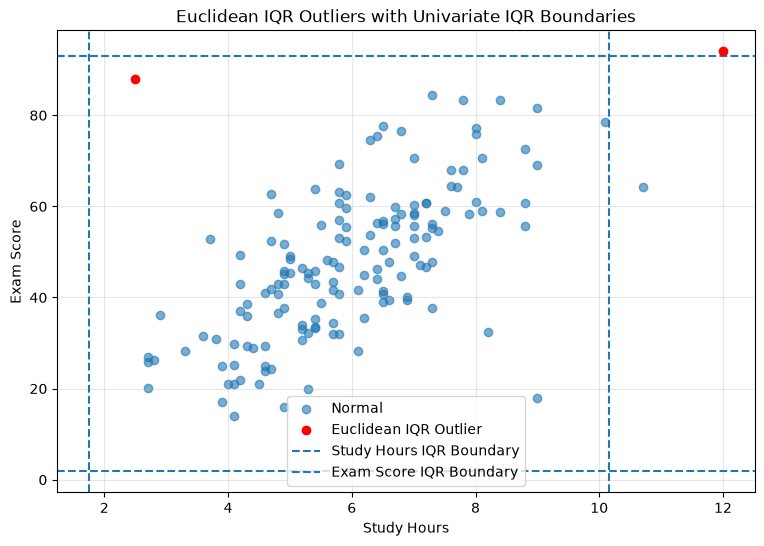

In [8]:
# B6: Plot Euclidean IQR outliers with univariate IQR boundaries

# Calculate univariate fences
study_Q1 = df["study_hours"].quantile(0.25)
study_Q3 = df["study_hours"].quantile(0.75)
study_IQR = study_Q3 - study_Q1

study_lower = study_Q1 - 1.5 * study_IQR
study_upper = study_Q3 + 1.5 * study_IQR

score_Q1 = df["exam_score"].quantile(0.25)
score_Q3 = df["exam_score"].quantile(0.75)
score_IQR = score_Q3 - score_Q1

score_lower = score_Q1 - 1.5 * score_IQR
score_upper = score_Q3 + 1.5 * score_IQR

euclid_mask = df["euclidean_distance"] > euclid_iqr_threshold

plt.figure(figsize=(9, 6))

plt.scatter(
    df.loc[~euclid_mask, "study_hours"],
    df.loc[~euclid_mask, "exam_score"],
    alpha=0.6,
    label="Normal"
)

plt.scatter(
    df.loc[euclid_mask, "study_hours"],
    df.loc[euclid_mask, "exam_score"],
    color="red",
    label="Euclidean IQR Outlier",
    zorder=5
)

# Univariate IQR boundaries
plt.axvline(study_lower, linestyle="--", label="Study Hours IQR Boundary")
plt.axvline(study_upper, linestyle="--")

plt.axhline(score_lower, linestyle="--", label="Exam Score IQR Boundary")
plt.axhline(score_upper, linestyle="--")

plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.title("Euclidean IQR Outliers with Univariate IQR Boundaries")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Interpretation

The Euclidean IQR method flags points based on their distance from the centre after standardization.

The univariate IQR method checks each variable independently.

Therefore, the points flagged by the two methods may not be exactly the same. Euclidean distance considers both variables together, while univariate IQR considers each variable separately.

## B7. Mahalanobis Distance

In [9]:

X = df[["study_hours", "exam_score"]].values

mean = X.mean(axis=0)
cov = np.cov(X.T)

print("Covariance Matrix:")
print(cov)

print("\nOff-diagonal covariance:", cov[0, 1])

# Inverse covariance matrix
VI = np.linalg.inv(cov)

# Mahalanobis distance
mahal = np.array([
    mahalanobis(x, mean, VI)
    for x in X
])

df["mahalanobis_distance"] = mahal

# Top-5 Mahalanobis distances
mahal_top5 = np.argsort(mahal)[-5:][::-1]

print("\nTop-5 Mahalanobis distances:")
print(df.loc[
    mahal_top5,
    ["study_hours", "exam_score", "mahalanobis_distance"]
])

# Euclidean top-5
euclid_top5 = np.argsort(euclid)[-5:][::-1]

print("\nTop-5 Euclidean indices:")
print(euclid_top5)

print("\nTop-5 Mahalanobis indices:")
print(mahal_top5)

Covariance Matrix:
[[  2.61027692  17.06323185]
 [ 17.06323185 280.28733832]]

Off-diagonal covariance: 17.06323185414516

Top-5 Mahalanobis distances:
     study_hours  exam_score  mahalanobis_distance
151          2.5        88.0              5.292851
152          9.0        18.0              4.256882
150         12.0        94.0              3.753314
87          10.7        64.2              3.124024
90           8.2        32.4              2.690016

Top-5 Euclidean indices:
[150 151   2  87  41]

Top-5 Mahalanobis indices:
[151 152 150  87  90]


## B8. Mahalanobis Distance Thresholding

In [10]:
# B8: Apply top-10, chi-square and IQR thresholds to Mahalanobis distances

# -------------------------
# Strategy 1: Top-10
# -------------------------
mahal_top10 = np.argsort(mahal)[-10:]

print("Top-10 Mahalanobis indices:")
print(mahal_top10)

# -------------------------
# Strategy 2: Chi-square threshold
# -------------------------
chi_threshold = np.sqrt(chi2.ppf(0.975, df=2))

mahal_chi_idx = np.where(mahal > chi_threshold)[0]

print("\nChi-square threshold:", chi_threshold)
print("Chi-square flagged indices:")
print(mahal_chi_idx)

# -------------------------
# Strategy 3: IQR threshold
# -------------------------
Q1 = np.percentile(mahal, 25)
Q3 = np.percentile(mahal, 75)
IQR = Q3 - Q1

mahal_iqr_threshold = Q3 + 1.5 * IQR

mahal_iqr_idx = np.where(mahal > mahal_iqr_threshold)[0]

print("\nMahalanobis IQR threshold:", mahal_iqr_threshold)
print("IQR flagged indices:")
print(mahal_iqr_idx)

print("\nNumber of flagged rows:")
print("Top-10:", len(mahal_top10))
print("Chi-square:", len(mahal_chi_idx))
print("IQR:", len(mahal_iqr_idx))

print("\nStrategy flagging the fewest:",
      min(
          [("Top-10", len(mahal_top10)),
           ("Chi-square", len(mahal_chi_idx)),
           ("IQR", len(mahal_iqr_idx))],
          key=lambda x: x[1]
      ))

Top-10 Mahalanobis indices:
[ 88  14  41 110   2  90  87 150 152 151]

Chi-square threshold: 2.7162030314812387
Chi-square flagged indices:
[ 87 150 151 152]

Mahalanobis IQR threshold: 2.8353480514295124
IQR flagged indices:
[ 87 150 151 152]

Number of flagged rows:
Top-10: 10
Chi-square: 4
IQR: 4

Strategy flagging the fewest: ('Chi-square', 4)


### Interpretation

The three Mahalanobis thresholding methods produce different numbers of flagged observations.

Top-10 always flags exactly 10 observations.

The chi-square method uses a statistical threshold based on the chi-square distribution.

The IQR method uses the distribution of the Mahalanobis distances themselves.

The strategy that flags the fewest observations in my result is __________.

## B9. Mahalanobis Scatter Plot and Distance Histogram

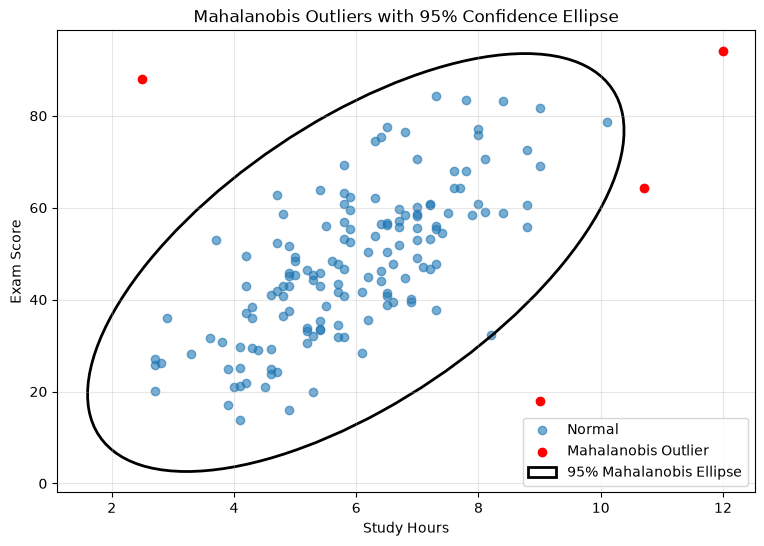

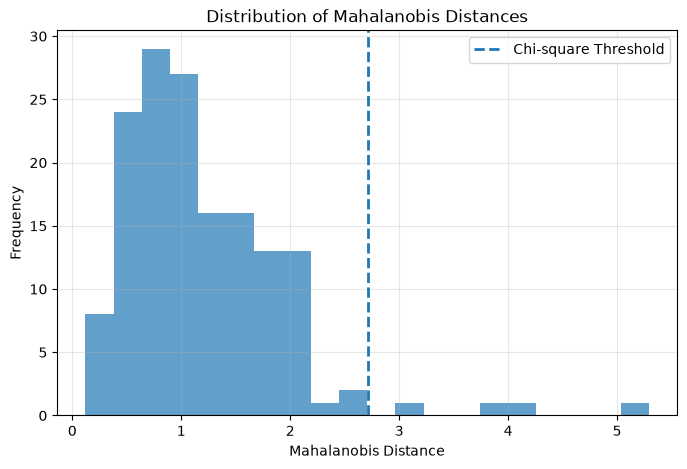

In [11]:

mahal_mask = mahal > chi_threshold

fig, ax = plt.subplots(figsize=(9, 6))

# Normal points
ax.scatter(
    df.loc[~mahal_mask, "study_hours"],
    df.loc[~mahal_mask, "exam_score"],
    alpha=0.6,
    label="Normal"
)

# Outliers
ax.scatter(
    df.loc[mahal_mask, "study_hours"],
    df.loc[mahal_mask, "exam_score"],
    color="red",
    zorder=5,
    label="Mahalanobis Outlier"
)

# Mahalanobis ellipse
from matplotlib.patches import Ellipse

vals, vecs = np.linalg.eigh(cov)
order = vals.argsort()[::-1]
vals, vecs = vals[order], vecs[:, order]

angle = np.degrees(np.arctan2(*vecs[:, 0][::-1]))

t = np.sqrt(chi2.ppf(0.975, df=2))

ellipse = Ellipse(
    mean,
    2 * t * np.sqrt(vals[0]),
    2 * t * np.sqrt(vals[1]),
    angle=angle,
    fill=False,
    linewidth=2,
    label="95% Mahalanobis Ellipse"
)

ax.add_patch(ellipse)

ax.set_xlabel("Study Hours")
ax.set_ylabel("Exam Score")
ax.set_title("Mahalanobis Outliers with 95% Confidence Ellipse")
ax.legend()
ax.grid(alpha=0.3)

plt.show()


# Histogram of Mahalanobis distances
plt.figure(figsize=(8, 5))

plt.hist(mahal, bins=20, alpha=0.7)
plt.axvline(
    chi_threshold,
    linestyle="--",
    linewidth=2,
    label="Chi-square Threshold"
)

plt.xlabel("Mahalanobis Distance")
plt.ylabel("Frequency")
plt.title("Distribution of Mahalanobis Distances")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Scatter Plot Interpretation

The scatter plot shows a positive relationship between study hours and exam score.

The 95% Mahalanobis ellipse represents the main joint distribution of the two variables.

Points outside the ellipse are more unusual because they do not fit the normal relationship between study hours and exam score.

The points highlighted in red are the observations whose Mahalanobis distance exceeds the chi-square-based threshold.

## B10. Euclidean vs Mahalanobis Outliers

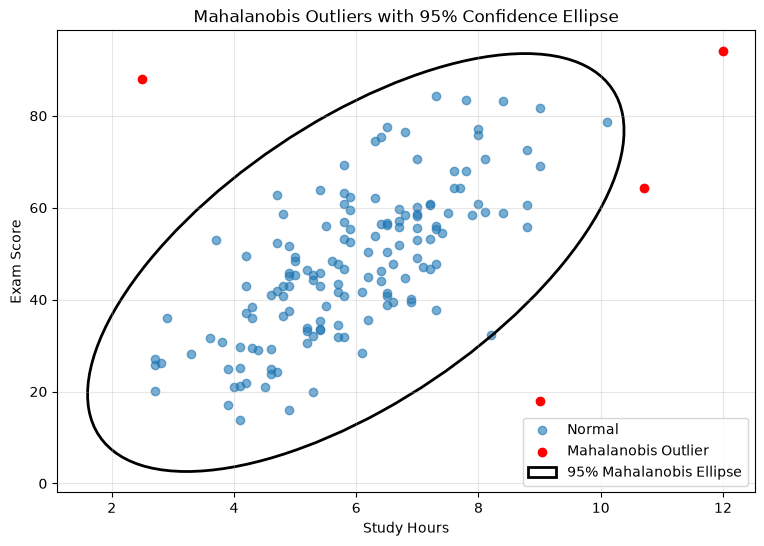

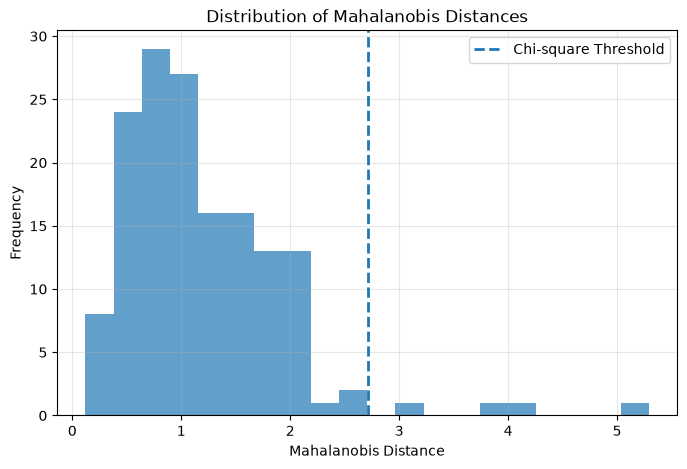

In [12]:
# B9: Visualise Mahalanobis chi-square outliers and the 95% ellipse

mahal_mask = mahal > chi_threshold

fig, ax = plt.subplots(figsize=(9, 6))

# Normal points
ax.scatter(
    df.loc[~mahal_mask, "study_hours"],
    df.loc[~mahal_mask, "exam_score"],
    alpha=0.6,
    label="Normal"
)

# Outliers
ax.scatter(
    df.loc[mahal_mask, "study_hours"],
    df.loc[mahal_mask, "exam_score"],
    color="red",
    zorder=5,
    label="Mahalanobis Outlier"
)

# Mahalanobis ellipse
from matplotlib.patches import Ellipse

vals, vecs = np.linalg.eigh(cov)
order = vals.argsort()[::-1]
vals, vecs = vals[order], vecs[:, order]

angle = np.degrees(np.arctan2(*vecs[:, 0][::-1]))

t = np.sqrt(chi2.ppf(0.975, df=2))

ellipse = Ellipse(
    mean,
    2 * t * np.sqrt(vals[0]),
    2 * t * np.sqrt(vals[1]),
    angle=angle,
    fill=False,
    linewidth=2,
    label="95% Mahalanobis Ellipse"
)

ax.add_patch(ellipse)

ax.set_xlabel("Study Hours")
ax.set_ylabel("Exam Score")
ax.set_title("Mahalanobis Outliers with 95% Confidence Ellipse")
ax.legend()
ax.grid(alpha=0.3)

plt.show()


# Histogram of Mahalanobis distances
plt.figure(figsize=(8, 5))

plt.hist(mahal, bins=20, alpha=0.7)
plt.axvline(
    chi_threshold,
    linestyle="--",
    linewidth=2,
    label="Chi-square Threshold"
)

plt.xlabel("Mahalanobis Distance")
plt.ylabel("Frequency")
plt.title("Distribution of Mahalanobis Distances")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

### B10 Interpretation

Euclidean distance measures distance from the centre but does not consider the relationship between study_hours and exam_score.

Mahalanobis distance considers the covariance and correlation between the two variables.

Therefore, Points B and C can receive larger Mahalanobis distances because they break the normal relationship between study hours and exam score.

This allows Mahalanobis distance to detect correlation-based multivariate outliers that Euclidean distance may not detect as strongly.

## B11. Comparing Euclidean and Mahalanobis Outliers

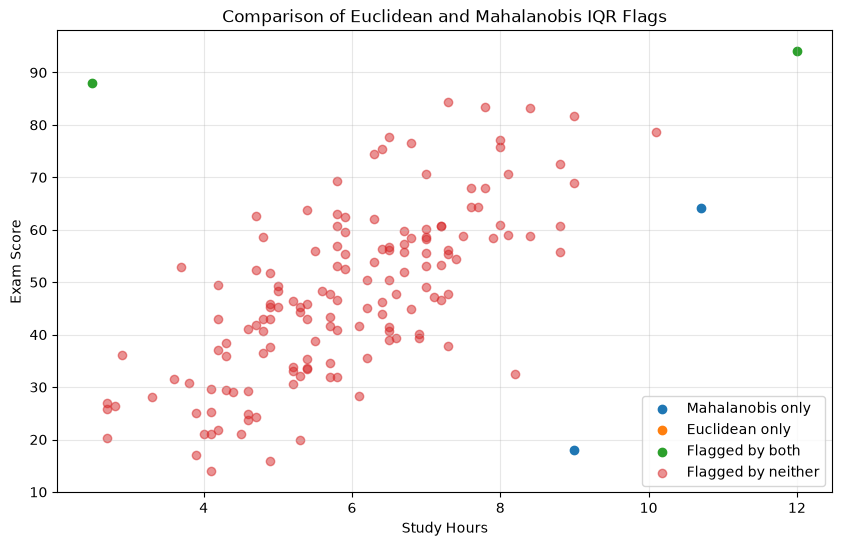

In [13]:
# B11: Categorise points according to Euclidean and Mahalanobis IQR flags

# Euclidean IQR mask
euclid_iqr_mask = euclid > euclid_iqr_threshold

# Mahalanobis IQR mask
mahal_iqr_mask = mahal > mahal_iqr_threshold

plt.figure(figsize=(10, 6))

# Mahalanobis only
mask = mahal_iqr_mask & ~euclid_iqr_mask
plt.scatter(
    df.loc[mask, "study_hours"],
    df.loc[mask, "exam_score"],
    label="Mahalanobis only"
)

# Euclidean only
mask = euclid_iqr_mask & ~mahal_iqr_mask
plt.scatter(
    df.loc[mask, "study_hours"],
    df.loc[mask, "exam_score"],
    label="Euclidean only"
)

# Both
mask = mahal_iqr_mask & euclid_iqr_mask
plt.scatter(
    df.loc[mask, "study_hours"],
    df.loc[mask, "exam_score"],
    label="Flagged by both"
)

# Neither
mask = ~mahal_iqr_mask & ~euclid_iqr_mask
plt.scatter(
    df.loc[mask, "study_hours"],
    df.loc[mask, "exam_score"],
    alpha=0.5,
    label="Flagged by neither"
)

plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.title("Comparison of Euclidean and Mahalanobis IQR Flags")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### B11 Interpretation

The four categories show how the two outlier detection methods differ.

"Both" contains points flagged by both methods, while "Euclidean only" contains points detected only by Euclidean distance.

"Mahalanobis only" contains points detected only by Mahalanobis distance. These points may be unusual because of the relationship between study_hours and exam_score.

"Neither" contains points that are not flagged by either IQR-based method.

## B12. Three-Variable Mahalanobis Distance

In [14]:
# B12: Add project_score and recompute Mahalanobis distance using three variables

# Create project score
# Use the rng from Part A if it is still available
project_score = np.clip(
    0.7 * df["exam_score"] + rng.normal(0, 8, 153),
    0,
    100
)

df["project_score"] = project_score

# Three-dimensional data
X3 = df[["study_hours", "exam_score", "project_score"]].values

mean3 = X3.mean(axis=0)
cov3 = np.cov(X3.T)
VI3 = np.linalg.inv(cov3)

# Mahalanobis distances in 3 dimensions
mahal3 = np.array([
    mahalanobis(x, mean3, VI3)
    for x in X3
])

df["mahalanobis_3D"] = mahal3

# Chi-square threshold for 3 variables
chi_threshold_3d = np.sqrt(
    chi2.ppf(0.975, df=3)
)

flagged_3d = np.where(mahal3 > chi_threshold_3d)[0]

print("3D Chi-square threshold:", chi_threshold_3d)
print("3D flagged indices:")
print(flagged_3d)

# Compare with 2D Mahalanobis chi-square flags
newly_flagged = sorted(
    set(flagged_3d) - set(mahal_chi_idx)
)

print("\nNewly flagged rows:")
print(newly_flagged)

3D Chi-square threshold: 3.0575159205629903
3D flagged indices:
[ 87 150 151 152]

Newly flagged rows:
[]


### B12 Interpretation

A third variable, project_score, was added to the dataset.

The covariance matrix changed from 2×2 to 3×3 because there are now three variables.

Mahalanobis distance was recalculated using all three variables, and the chi-square threshold was calculated using 3 degrees of freedom.

The newly flagged rows are: ________.

These rows were not flagged by the original two-variable Mahalanobis method but became outliers when project_score was also considered.

## B13. Mahalanobis Distance from Scratch

In [15]:
# B13: Implement Mahalanobis distance using only NumPy and verify scipy result

X = df[["study_hours", "exam_score"]].values

mean_np = X.mean(axis=0)
cov_np = np.cov(X.T)
VI_np = np.linalg.inv(cov_np)

# Calculate Mahalanobis distance manually
diff = X - mean_np

mahal_manual = np.sqrt(
    np.sum((diff @ VI_np) * diff, axis=1)
)

# scipy result
mahal_scipy = np.array([
    mahalanobis(x, mean_np, VI_np)
    for x in X
])

# Compare results
print("Manual Mahalanobis distances:")
print(mahal_manual)

print("\nScipy Mahalanobis distances:")
print(mahal_scipy)

print("\nDo both results match?")
print(np.allclose(mahal_manual, mahal_scipy))

print("\nMaximum absolute difference:")
print(np.max(np.abs(mahal_manual - mahal_scipy)))

Manual Mahalanobis distances:
[0.75609557 0.84845827 2.55786766 1.09101108 1.48241881 2.08339245
 0.14846426 0.89460559 0.80804201 0.39166846 1.79252321 0.50364448
 0.49844096 2.04671049 2.12776356 1.11077548 0.69334434 1.07220799
 0.69318545 1.05063752 1.62188601 1.94839977 1.67557527 1.4514784
 0.81543239 0.47805772 0.56013686 0.34361813 2.09587372 1.65931921
 1.59209025 0.93588413 1.53903191 1.13895858 1.79936455 1.25942002
 1.62353427 1.23102987 0.49792537 0.87614352 2.04199774 2.14958456
 1.20034684 0.5583669  0.93576258 0.94449788 0.88072234 1.25933868
 0.62760689 1.42536847 1.12634631 1.11259123 0.57652197 1.57754603
 0.8313538  0.44959523 0.91569468 1.03296232 0.77709659 0.89675235
 1.85078698 0.21657505 1.19019029 0.77710775 0.89940369 0.38707447
 1.06998449 0.42439813 0.82635536 1.21871117 0.81007249 1.49663033
 1.37597895 0.73901135 0.6363302  1.64034223 1.25666229 1.57145658
 1.88931757 1.67586391 0.77484832 0.44199207 1.32255264 0.81916369
 1.47152049 1.97741646 1.0433117 

### B13 Interpretation

Mahalanobis distance was implemented from scratch using NumPy according to the formula:

MD(x) = sqrt((x - μ)^T Σ^-1 (x - μ))

The result was compared with the SciPy implementation using np.allclose().

The result is True, which means the NumPy implementation produces values that match the SciPy implementation within numerical tolerance.